# Chiral quasi-Bound State in the Continuum (qBIC) & Local Optical Chirality Enhancement

This notebook demonstrates the calculation of circular dichroism and local electromagnetic field enhancement $(\mathbf{E}, \mathbf{H})$ using **EMUstack**.

---

## 1. Physics & Theoretical Background

### Quasi-Bound States in the Continuum (qBICs)
A **Bound State in the Continuum (BIC)** is an eigenstate with infinite radiative lifetime that resides within the continuous spectrum of propagating radiation channels.
In dielectric metasurfaces, symmetry-protected BICs occur when the spatial symmetry of the unit cell decouples the resonant mode from the radiative continuum at normal incidence ($\mathbf{k}_\parallel = \mathbf{0}$).

By introducing an in-plane geometric asymmetry parameter $\alpha$ (such as tilting dimer bars with asymmetric angles $\theta_1 = \theta_0 + \alpha$ and $\theta_2 = -\theta_0$), the symmetry-protected BIC transitions into a **quasi-BIC (qBIC)** with a finite, ultra-high quality factor scaling as:
$$Q \propto \alpha^{-2}$$

### Intrinsic Chirality & Circular Dichroism
When the asymmetry $\alpha$ breaks both in-plane mirror symmetry and inversion symmetry, the structure exhibits **intrinsic chirality**. Under circularly polarized light:
- **Left Circularly Polarized (LCP)**: $\mathbf{E}_{\text{LCP}} = \frac{1}{\sqrt{2}}(\hat{x} + i\hat{y}) e^{i k_0 z}$
- **Right Circularly Polarized (RCP)**: $\mathbf{E}_{\text{RCP}} = \frac{1}{\sqrt{2}}(\hat{x} - i\hat{y}) e^{i k_0 z}$

The interaction strength between the chiral qBIC mode and the two circular polarizations differs dramatically, resulting in giant **Circular Dichroism (CD)**:
$$\mathrm{CD} = T_{\text{LCP}} - T_{\text{RCP}}$$

### Local Optical Chirality Density
The time-averaged optical chirality density $C(\mathbf{r})$ (Lipkin 1964; Tang & Cohen, *Science* 2011) is defined as:
$$C(\mathbf{r}) = -\frac{\omega \varepsilon_0}{2} \operatorname{Im}\left( \mathbf{E}^*(\mathbf{r}) \cdot \mathbf{B}(\mathbf{r}) \right) = -\frac{k_0}{2} \operatorname{Im}\left( \mathbf{E}^* \cdot \mathbf{H} \right)$$
where $k_0 = \omega/c = 2\pi / \lambda$.

For incident circularly polarized light (CPL) in free space, the background chirality is $|C_{\text{CPL}}| = \frac{k_0}{2} |E_0|^2$.
The normalized local optical chirality enhancement factor is:
$$\hat{C}(\mathbf{r}) = \frac{C(\mathbf{r})}{|C_{\text{CPL}}|}$$


In [1]:
import os
import sys
import numpy as np
import matplotlib.pyplot as plt

# Add EMUstack backend and mesh templates to path
backend_dir = os.path.abspath("../backend")
mesh_dir = os.path.join(backend_dir, "data", "meshes")
for d in (backend_dir, mesh_dir):
    if d not in sys.path:
        sys.path.insert(0, d)

import objects
import materials
import plotting
import field_eval
from stack import Stack

plotting.clear_previous()
print("EMUstack loaded successfully.")



##################################################################
EMUstack is brought to you by Bjorn Sturmberg, Kokou Dossou, 
Felix Lawrence & Lindsay Botton, with support from CUDOS & ARENA
Starting EMUstack calculation ...
##################################################################

EMUstack loaded successfully.


## 2. Metasurface Geometry Setup

We model a unit cell with period $P = 700\text{ nm}$ containing a tilted dielectric dimer ($n = 3.5$) in air ($n = 1.0$).
The tilt angles of the two resonators are:
$$\theta_1 = \theta_0 + \alpha, \quad \theta_2 = -\theta_0$$
where $\theta_0 = 0.25\text{ rad}$ and $\alpha = 0.15$ breaks mirror symmetry.


In [2]:
period = 700.0   # nm
height = 300.0   # nm
alpha = 0.15     # Asymmetry parameter
num_bms = 18     # Number of Bloch modes

# Structured layer
qbic_layer = objects.NanoStruct(
    "2D_array", period, 200.0,
    geo_file="chiral_qbic_template.py",
    geo_params={"alpha": alpha, "theta0": 0.25, "rx": 0.09, "ry": 0.28, "gap": 0.36, "lc": 0.18, "lc2": 1.8},
    background=materials.Material(1.0),
    inclusion_a=materials.Material(3.5),
    height_nm=height,
    plotting_fields=1
)

# Semi-infinite superstrate and substrate (air)
sup = objects.ThinFilm(period=period, height_nm="semi_inf", material=materials.Material(1.0))
sub = objects.ThinFilm(period=period, height_nm="semi_inf", material=materials.Material(1.0))
print("Metasurface geometry configured.")


Metasurface geometry configured.


## 3. Spectral Calculation: Circular Dichroism (CD)

We calculate the transmittance $T$ and reflectance $R$ under Left Circular Polarization (LCP) and Right Circular Polarization (RCP).


In [3]:
wavelengths = np.linspace(685.0, 725.0, 9)

T_rcp, R_rcp = [], []
T_lcp, R_lcp = [], []
res_stack_rcp = None
res_wl = 700.0

for wl in wavelengths:
    light = objects.Light(wl, max_order_PWs=1, theta=0.0, phi=0.0)
    sim_layer = qbic_layer.calc_modes(light, num_BMs=num_bms)
    sim_sup = sup.calc_modes(light)
    sim_sub = sub.calc_modes(light)
    
    # RCP
    stk_rcp = Stack([sim_sub, sim_layer, sim_sup])
    stk_rcp.calc_scat(pol="RCP")
    T_rcp.append(float(stk_rcp.t_list[-1]))
    R_rcp.append(float(stk_rcp.r_list[-1]))
    
    # LCP
    stk_lcp = Stack([sim_sub, sim_layer, sim_sup])
    stk_lcp.calc_scat(pol="LCP")
    T_lcp.append(float(stk_lcp.t_list[-1]))
    R_lcp.append(float(stk_lcp.r_list[-1]))
    
    if abs(wl - 700.0) < 1.0 or res_stack_rcp is None:
        res_stack_rcp = stk_rcp
        res_wl = wl

T_rcp = np.array(T_rcp)
R_rcp = np.array(R_rcp)
T_lcp = np.array(T_lcp)
R_lcp = np.array(R_lcp)
CD = T_lcp - T_rcp
print("Spectral sweep completed.")


Spectral sweep completed.


## 4. Transmission & Reflection Spectra

Plotting the sharp asymmetric Fano resonances and Circular Dichroism across the qBIC resonance.


<ipython-input-1-9ad651bfb522>:24: UserWarning: FigureCanvasPdf is non-interactive, and thus cannot be shown
  plt.show()


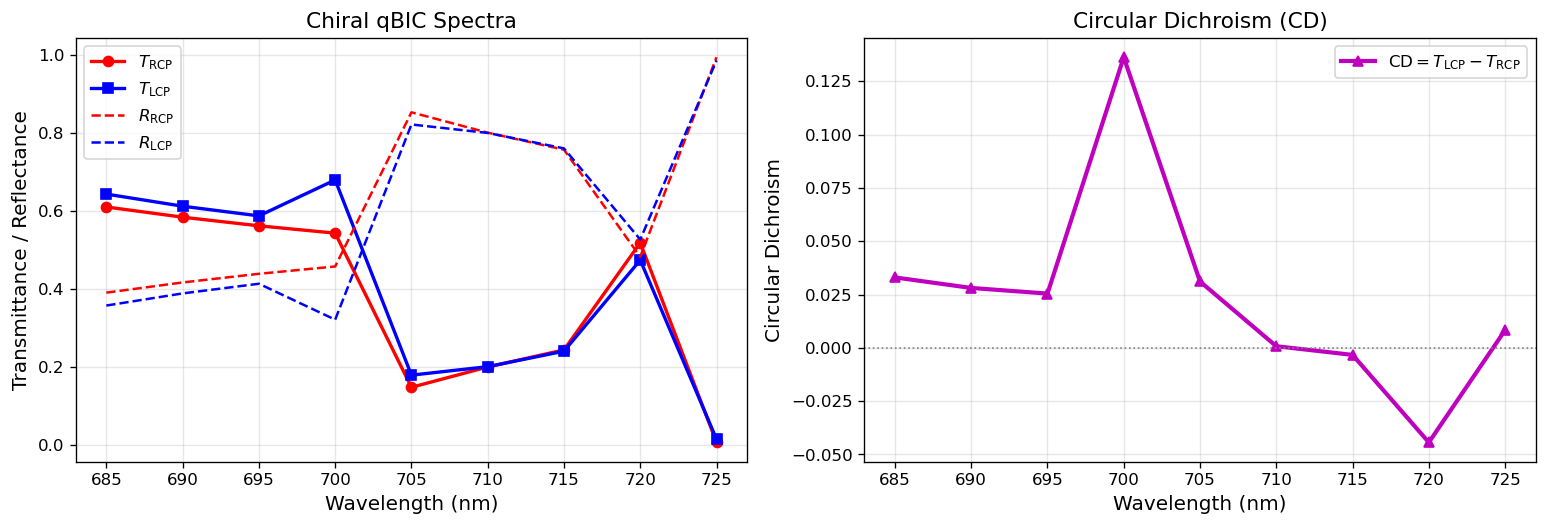

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5), dpi=120)

# Spectra
ax1.plot(wavelengths, T_rcp, "r-o", lw=2, label=r"$T_{\mathrm{RCP}}$")
ax1.plot(wavelengths, T_lcp, "b-s", lw=2, label=r"$T_{\mathrm{LCP}}$")
ax1.plot(wavelengths, R_rcp, "r--", lw=1.5, label=r"$R_{\mathrm{RCP}}$")
ax1.plot(wavelengths, R_lcp, "b--", lw=1.5, label=r"$R_{\mathrm{LCP}}$")
ax1.set_xlabel("Wavelength (nm)", fontsize=12)
ax1.set_ylabel("Transmittance / Reflectance", fontsize=12)
ax1.set_title("Chiral qBIC Spectra", fontsize=13)
ax1.legend(loc="best", frameon=True)
ax1.grid(True, alpha=0.3)

# Circular Dichroism
ax2.plot(wavelengths, CD, "m-^", lw=2.5, label=r"$\mathrm{CD} = T_{\mathrm{LCP}} - T_{\mathrm{RCP}}$")
ax2.axhline(0, color="gray", linestyle=":", lw=1)
ax2.set_xlabel("Wavelength (nm)", fontsize=12)
ax2.set_ylabel("Circular Dichroism", fontsize=12)
ax2.set_title("Circular Dichroism (CD)", fontsize=13)
ax2.legend(loc="best", frameon=True)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## 5. Near-Field Electromagnetic Reconstruction & Optical Chirality

EMUstack provides the full local electromagnetic field vectors $\mathbf{E}$ and $\mathbf{H}$ through `fields_interpolator_in_plane(..., return_H=True)`.
This returns a `FieldBundle` containing 14 interpolators for all 6 complex components $(E_x, E_y, E_z, H_x, H_y, H_z)$ and total norms $(|E|, |H|)$.
We define a helper function `compute_optical_chirality` that operates on the returned $\mathbf{E}$ and $\mathbf{H}$ to evaluate the local optical chirality density:
$$C = -\frac{k_0}{2} \operatorname{Im}(\mathbf{E}^* \cdot \mathbf{H})$$
and the normalized local chirality enhancement factor:
$$\hat{C} = \frac{C}{|C_{\mathrm{CPL}}|}, \quad \text{where } |C_{\mathrm{CPL}}| = \frac{k_0}{2} |E_0|^2.$$


In [5]:
def compute_optical_chirality(Ex, Ey, Ez, Hx, Hy, Hz, k0=1.0, E0=1.0):
    """Helper function operating on local E and H fields to compute optical chirality.
    
    C = -0.5 * k0 * Im(E* . H)
    C_hat = C / |C_CPL| where |C_CPL| = 0.5 * k0 * |E0|^2
    """
    E_dot_H = np.conj(Ex) * Hx + np.conj(Ey) * Hy + np.conj(Ez) * Hz
    C = -0.5 * float(k0) * np.imag(E_dot_H)
    C_cpl = 0.5 * float(k0) * (abs(E0)**2)
    C_hat = C / max(C_cpl, 1e-15)
    return C, C_hat

z_eval = height / 2.0  # Center plane of the metasurface
bundle = plotting.fields_interpolator_in_plane(res_stack_rcp, lay_interest=1, z_value=z_eval, return_H=True)

# Evaluate on Cartesian grid
grid_n = 70
xg = np.linspace(0.02, 0.98, grid_n)
yg = np.linspace(0.02, 0.98, grid_n)
X, Y = np.meshgrid(xg, yg)

# Local E and H components from EMUstack
Ex = bundle.Ex(X, Y)
Ey = bundle.Ey(X, Y)
Ez = bundle.Ez(X, Y)
Hx = bundle.Hx(X, Y)
Hy = bundle.Hy(X, Y)
Hz = bundle.Hz(X, Y)
E_norm = bundle.AbsE(X, Y)
H_norm = bundle.AbsH(X, Y)

# Optical chirality computed via helper function operating on E and H
k0 = 2.0 * np.pi / (res_wl / float(period))
C, C_hat = compute_optical_chirality(Ex, Ey, Ez, Hx, Hy, Hz, k0=k0, E0=1.0)

print("Near-field evaluation complete:")
print(f"  Peak |E|^2 / |E0|^2 = {np.nanmax(E_norm**2):.2f}")
print(f"  Peak |H|^2 / |H0|^2 = {np.nanmax(H_norm**2):.2f}")
print(f"  Peak |C_hat|        = {np.nanmax(np.abs(C_hat)):.2f}")


Near-field evaluation complete:
  Peak |E|^2 / |E0|^2 = 45.17
  Peak |H|^2 / |H0|^2 = 230.09
  Peak |C_hat|        = 18.94


## 6. Near-Field Spatial Maps ($|E|^2$, $|H|^2$, and $\hat{C}$)

Spatial visualization of electric intensity, magnetic intensity, and local optical chirality enhancement in the unit cell.


/opt/miniconda3/envs/fem-scattering/lib/python3.14/site-packages/numpy/lib/_function_base_impl.py:4786: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  arr.partition(
<ipython-input-1-354b9a718f7b>:23: UserWarning: FigureCanvasPdf is non-interactive, and thus cannot be shown
  plt.show()


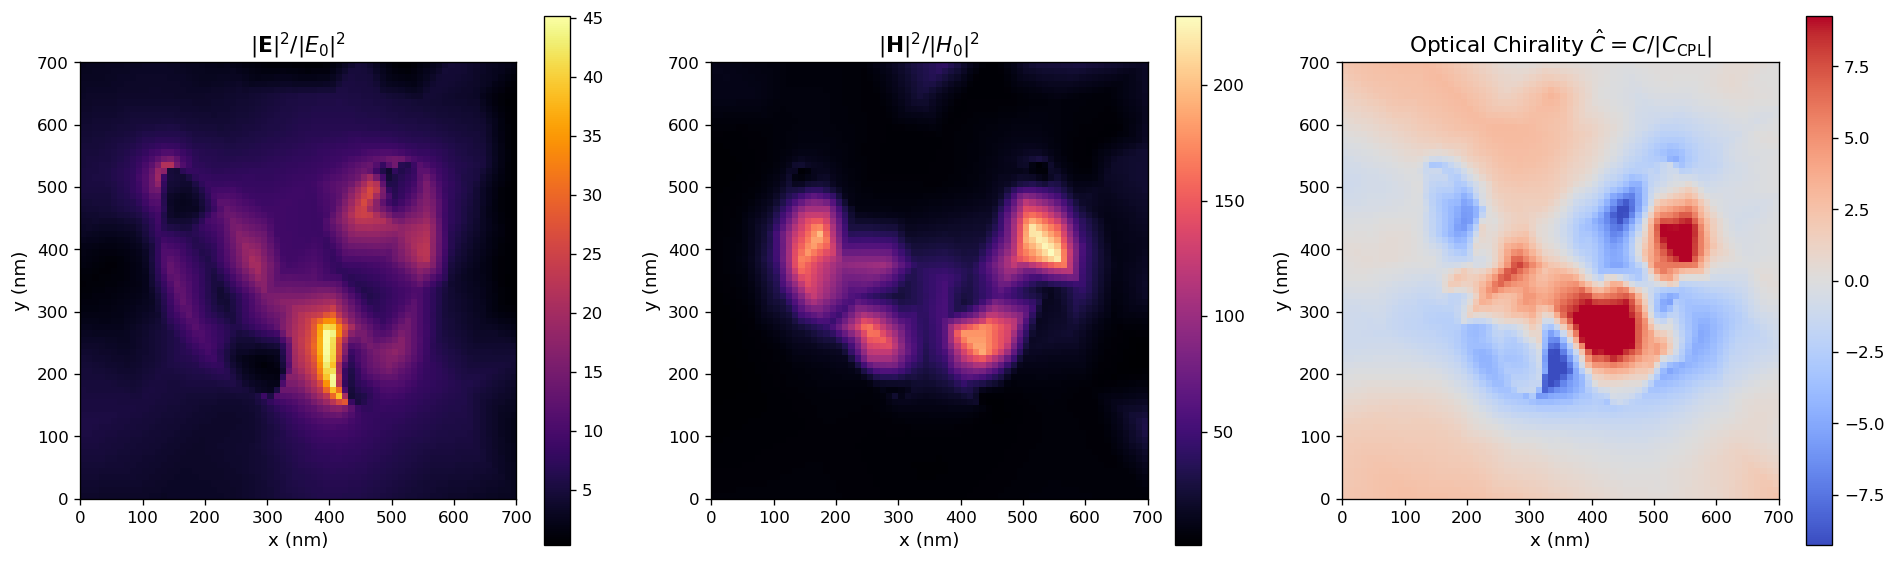

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), dpi=120)

im0 = axes[0].imshow(E_norm**2, origin="lower", extent=[0, period, 0, period], cmap="inferno")
axes[0].set_title(r"$|\mathbf{E}|^2 / |E_0|^2$", fontsize=13)
axes[0].set_xlabel("x (nm)", fontsize=11)
axes[0].set_ylabel("y (nm)", fontsize=11)
plt.colorbar(im0, ax=axes[0])

im1 = axes[1].imshow(H_norm**2, origin="lower", extent=[0, period, 0, period], cmap="magma")
axes[1].set_title(r"$|\mathbf{H}|^2 / |H_0|^2$", fontsize=13)
axes[1].set_xlabel("x (nm)", fontsize=11)
axes[1].set_ylabel("y (nm)", fontsize=11)
plt.colorbar(im1, ax=axes[1])

vmax_c = max(float(np.nanpercentile(np.abs(C_hat), 98)), 1.0)
im2 = axes[2].imshow(C_hat, origin="lower", extent=[0, period, 0, period], cmap="coolwarm", vmin=-vmax_c, vmax=vmax_c)
axes[2].set_title(r"Optical Chirality $\hat{C} = C / |C_{\mathrm{CPL}}|$", fontsize=13)
axes[2].set_xlabel("x (nm)", fontsize=11)
axes[2].set_ylabel("y (nm)", fontsize=11)
plt.colorbar(im2, ax=axes[2])

plt.tight_layout()
plt.show()
